# Proyecto 3: Neural Style Transfer with PyTorch and Keras



<table>
  <tr>
    <th colspan="2">👥 <b>Team Members</b></th>
  </tr>
  <tr>
    <td><b>1.</b></td>
    <td><b>Diego Ubaldo</b></td>
  </tr>
  <tr>
    <td><b>2.</b></td>
    <td><b>Taban Ngunar</b></td>
  </tr>
</table>

---

In this proyecto we mix the **content** of a photo with the **style** of a famous painting. We do it with **PyTorch** (main implementation, 36 images) and with **Keras / TensorFlow** (second implementation), and then we compare them.

**The idea (Gatys et al., 2016):**
- We use a pretrained **VGG19** network. We never train it. We only read what happens inside it.
- Deep layers describe *what is in the picture* (people, buildings, trees). This is the **content**.
- The **Gram matrix** of several layers tells which features appear together. This describes the *look*: colors, brush strokes, texture. This is the **style**.
- We start from the photo and change its pixels until the content matches the photo and the style matches the painting.

**Controls implemented (the assignment asks for at least two):**
- (a) Content vs. style balance
- (b) Texture control
- (d) Color control

**Sections**
1. Environment and libraries
2. Images (6 content images, 6 painters)
3. PyTorch implementation (with cache and checkpoints)
4. PyTorch: all 36 combinations
5. PyTorch: control experiments
6. Keras implementation (with cache and checkpoints)
7. Keras: results and controls
8. PyTorch vs. Keras comparison
9. Conclusions and references

**Saved automatically:** results, checkpoints and loss logs of both frameworks go to `cache/`, so re-running the notebook is fast.

## 1. Environment and libraries

The notebook runs **locally** on a PC (no Colab, no AWS). A GPU is optional. If a GPU is found, PyTorch uses it automatically.

- Recommended Python: 3.10 to 3.12
- Libraries: PyTorch + torchvision, TensorFlow (Keras), NumPy, Pillow, Matplotlib



The cell below installs everything. Run it once, then restart the kernel.

In [1]:
%pip install torch torchvision tensorflow matplotlib pillow numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


The next cell imports the libraries and prints the exact versions used.

In [2]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision
from torchvision import models, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Python     :", sys.version.split()[0])
print("PyTorch    :", torch.__version__)
print("torchvision:", torchvision.__version__)
print("NumPy      :", np.__version__)
print("Device     :", device)

Python     : 3.11.9
PyTorch    : 2.15.0+cpu
torchvision: 0.29.2+cpu
NumPy      : 2.4.6
Device     : cpu


## 2. Images

Folder structure expected next to this notebook:

```
images/content/portrait.jpg, group.jpg, landscape.jpg, architecture.jpg, still_life.jpg, savannah.jpg
images/style/van_gogh.jpg, picasso.jpg, munch.jpg, klimt.jpg, manet.jpg, vofan.jpg
```

**Content categories (6):** individual portrait, group portrait, landscape, exterior architecture, still life, and savannah.

**Painters (6)**
- Van Gogh: *The Starry Night*
- Picasso: *Weeping Woman*
- Edvard Munch: *The Scream*
- Gustav Klimt: *The Kiss*
- Edouard Manet: *Olympia*
- Vofan: *just a random paint from the vietnamese artist*

Two settings control speed. `IMG_SIZE` is the longest side in pixels (256 is fast on CPU). `STEPS` is the number of optimization steps per image.

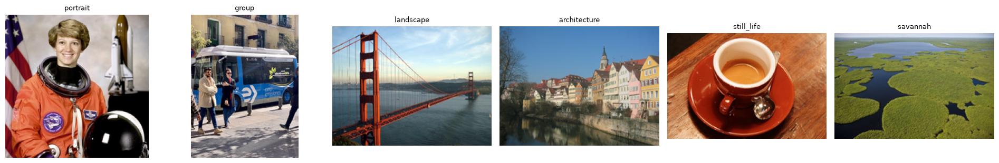

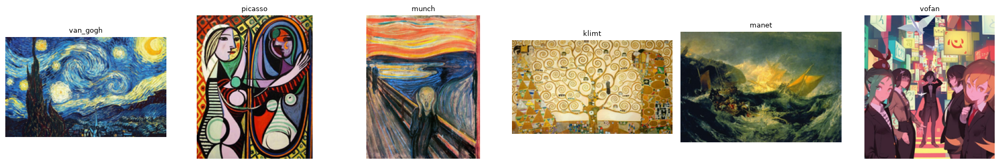

In [3]:
CONTENT = {
    "portrait":     "images/content/portrait.jpg",
    "group":        "images/content/group.jpg",
    "landscape":    "images/content/landscape.jpg",
    "architecture": "images/content/architecture.jpg",
    "still_life":   "images/content/still_life.jpg",
    "savannah":     "images/content/savannah.jpg",   # taban's preference selection
}
STYLE = {
    "van_gogh": "images/style/van_gogh.jpg",   # The Starry Night
    "picasso":  "images/style/picasso.jpg",    # Weeping Woman
    "munch":    "images/style/munch.jpg",      # The Scream
    "klimt":    "images/style/klimt.jpg",      # The Kiss
    "manet":    "images/style/manet.jpg",      # Olympia
    "vofan":    "images/style/vofan.jpg",      # ubaldo's preference selection
}

IMG_SIZE = 256     # longest side in pixels (256 fast on CPU, 384-512 with GPU)
STEPS    = 150     # optimization steps per image
os.makedirs("outputs", exist_ok=True)

def load_pil(src, longest_side):
    """Accepts a file path or a PIL image. Resizes so the longest side = longest_side."""
    img = Image.open(src).convert("RGB") if isinstance(src, str) else src
    s = longest_side / max(img.size)
    return img.resize((max(8, round(img.width * s)), max(8, round(img.height * s))), Image.LANCZOS)

def show_row(images, titles, size=3.2):
    fig, axs = plt.subplots(1, len(images), figsize=(size * len(images), size))
    axs = np.atleast_1d(axs)
    for ax, im, t in zip(axs, images, titles):
        ax.imshow(im); ax.set_title(t, fontsize=9); ax.axis("off")
    plt.tight_layout(); plt.show()

# Check that every file exists, then show them
missing = [p for p in list(CONTENT.values()) + list(STYLE.values()) if not os.path.exists(p)]
if missing:
    print("Missing image files:"); [print("  -", p) for p in missing]
else:
    show_row([load_pil(p, 200) for p in CONTENT.values()], list(CONTENT))
    show_row([load_pil(p, 200) for p in STYLE.values()], list(STYLE))

## 3. PyTorch implementation

### 3.1 Feature extractor (VGG19)

We load VGG19 pretrained on ImageNet and freeze it. Only the image will change.

- **Content layer:** `conv4_2` (deep layer, describes objects and layout).
- **Style layers:** `conv1_1` to `conv5_1` (from fine details to large shapes).
- **Gram matrix:** for a layer with `c` channels, we flatten the spatial size and compute `F @ F.T`. It tells which channels fire together, and it ignores *where* they fire. That is why it captures style and not layout.

In [4]:
vgg = models.vgg19(weights=models.VGG19_Weights.IMAGENET1K_V1).features.to(device).eval()
for m in vgg:
    if isinstance(m, nn.ReLU):
        m.inplace = False                  # in-place ReLU breaks gradients on the image
for p in vgg.parameters():
    p.requires_grad_(False)                # the network is frozen, only the image changes

LAYER_IDS     = {0: "conv1_1", 5: "conv2_1", 10: "conv3_1", 19: "conv4_1", 21: "conv4_2", 28: "conv5_1"}
STYLE_LAYERS  = ["conv1_1", "conv2_1", "conv3_1", "conv4_1", "conv5_1"]
CONTENT_LAYER = "conv4_2"

MEAN = torch.tensor([0.485, 0.456, 0.406], device=device).view(1, 3, 1, 1)
STD  = torch.tensor([0.229, 0.224, 0.225], device=device).view(1, 3, 1, 1)

def to_tensor(pil):
    return transforms.ToTensor()(pil).unsqueeze(0).to(device)

def to_pil(t):
    return transforms.ToPILImage()(t.detach().cpu().squeeze(0).clamp(0, 1))

def features(x):
    """Run VGG19 and keep the activations of the layers we need."""
    x = (x - MEAN) / STD
    out = {}
    for i, layer in enumerate(vgg[:29]):
        x = layer(x)
        if i in LAYER_IDS:
            out[LAYER_IDS[i]] = x
    return out

def gram(f):
    """Gram matrix = which channels fire together = style (colors, strokes, texture)."""
    _, c, h, w = f.shape
    f = f.view(c, h * w)
    return f @ f.t() / (c * h * w)

### 3.2 Saving results and checkpoints (so you never wait twice)

Style transfer is slow because it optimizes the pixels of every image. To avoid repeating work, the notebook saves things to the folder `cache/`:

| Folder | What is saved | Why |
|---|---|---|
| `cache/results/` | finished stylized images (PNG) | Re-running a finished image takes less than a second. |
| `cache/checkpoints/` | the image pixels and step number, saved every `CHUNK` steps | If the kernel stops or you close the laptop, the run **continues from the last checkpoint**. |
| `cache/logs/` | loss values (total, content, style), settings, run time (JSON) | This is the "training data". You can plot the loss curves any time. |

**How the cache stays correct:** every file name contains a short code (hash) made from the two images and all settings (`steps`, `style_w`, `style_scale`, `layer_w`, image size). If you change an image or a setting, the code changes and the notebook computes a new result. If nothing changes, it reuses the old one.

The VGG19 weights are also downloaded only once. PyTorch keeps them in its own cache (`~/.cache/torch`).

In [5]:
import hashlib, json, shutil, glob

CACHE_DIR = "cache"
RES_DIR   = f"{CACHE_DIR}/results"
CKPT_DIR  = f"{CACHE_DIR}/checkpoints"
LOG_DIR   = f"{CACHE_DIR}/logs"
for d in (RES_DIR, CKPT_DIR, LOG_DIR):
    os.makedirs(d, exist_ok=True)

CHUNK = 25   # a checkpoint is saved every 25 steps

def cache_info():
    for d in (RES_DIR, CKPT_DIR, LOG_DIR):
        files = glob.glob(f"{d}/*")
        mb = sum(os.path.getsize(f) for f in files) / 1e6
        print(f"{d:25s} {len(files):3d} files  {mb:7.1f} MB")

def clear_cache():
    """Deletes everything in cache/ (use only if you want to recompute from zero)."""
    shutil.rmtree(CACHE_DIR, ignore_errors=True)
    for d in (RES_DIR, CKPT_DIR, LOG_DIR):
        os.makedirs(d, exist_ok=True)
    print("cache cleared")

### 3.3 Style transfer function and the three controls

The total loss is:

`loss = content_w * content_loss + style_w * style_loss`

- **Content loss:** MSE between the `conv4_2` features of the result and of the photo.
- **Style loss:** weighted sum of MSE between the Gram matrices of the result and of the painting.
- We start from the photo and optimize the pixels with **L-BFGS**, which converges quickly. This helps because we run on CPU.

**Controls**
- **(a) Content vs. style balance:** the ratio `style_w / content_w`. Bigger means more style.
- **(b) Texture:**
  - `style_scale` resizes the painting before reading its style. A big painting gives large, coarse strokes. A small one gives fine texture.
  - `layer_w` sets how much each layer counts. Shallow layers give fine texture. Deep layers give large shapes.
- **(d) Color:** with `keep_color=True` we keep the *brightness* of the stylized image and take the *color* (Cb, Cr channels) from the original photo.

In [6]:

def keep_original_color(content_pil, stylized_pil):
    """Color control: luminance from the stylized image, color from the photo."""
    y, _, _ = stylized_pil.convert("YCbCr").split()
    _, cb, cr = content_pil.convert("YCbCr").split()
    return Image.merge("YCbCr", (y, cb, cr)).convert("RGB")

def _img_hash(pil):
    return hashlib.md5(pil.tobytes()).hexdigest()[:8]

def style_transfer(content_pil, style_pil, name="run", steps=STEPS, content_w=1.0, style_w=1e6,
                   layer_w=None, style_scale=1.0, keep_color=False, use_cache=True):
    """Style transfer with result cache + resumable checkpoints.
    name = readable label for the files (for example 'landscape__van_gogh')."""
    layer_w = layer_w or {l: 1 / len(STYLE_LAYERS) for l in STYLE_LAYERS}

    # The key depends on the images and on every setting that changes the result
    params = dict(size=content_pil.size, steps=steps, content_w=content_w, style_w=style_w,
                  layer_w=layer_w, style_scale=style_scale,
                  c_hash=_img_hash(content_pil), s_hash=_img_hash(style_pil))
    h = hashlib.md5(json.dumps(params, sort_keys=True, default=str).encode()).hexdigest()[:10]
    res_path = f"{RES_DIR}/{name}_{h}.png"
    ck_path  = f"{CKPT_DIR}/{name}_{h}.pt"
    log_path = f"{LOG_DIR}/{name}_{h}.json"

    def finish(img):                     # color control is applied AFTER the cache
        return keep_original_color(content_pil, img) if keep_color else img

    # 1) Finished result already on disk -> return it in a fraction of a second
    if use_cache and os.path.exists(res_path):
        print(f"[cache] {name} loaded from disk")
        return finish(Image.open(res_path).convert("RGB"))

    c_img = to_tensor(content_pil)
    s_img = to_tensor(load_pil(style_pil, round(max(content_pil.size) * style_scale)))
    with torch.no_grad():
        c_target = features(c_img)[CONTENT_LAYER]
        s_grams  = {l: gram(f) for l, f in features(s_img).items() if l in STYLE_LAYERS}

    # 2) Unfinished run on disk -> resume from the last checkpoint
    x, done, history = c_img.clone(), 0, []
    if use_cache and os.path.exists(ck_path):
        ck = torch.load(ck_path, map_location=device)
        x, done, history = ck["x"].to(device), ck["done"], ck["history"]
        print(f"[resume] {name} from step {done}/{steps}")
    x.requires_grad_(True)

    opt = torch.optim.LBFGS([x], max_iter=CHUNK, lr=1.0)

    def closure():
        with torch.no_grad():
            x.clamp_(0, 1)
        opt.zero_grad()
        f = features(x)
        c_loss = F.mse_loss(f[CONTENT_LAYER], c_target)
        s_loss = sum(layer_w[l] * F.mse_loss(gram(f[l]), s_grams[l]) for l in STYLE_LAYERS)
        loss = content_w * c_loss + style_w * s_loss
        loss.backward()
        history.append([loss.item(), c_loss.item(), s_loss.item()])   # training data
        return loss

    t0 = time.time()
    while done < steps:                                  # optimize in small chunks
        n = min(CHUNK, steps - done)
        opt.param_groups[0]["max_iter"] = n
        opt.step(closure)
        done += n
        torch.save({"x": x.detach().cpu(), "done": done, "history": history}, ck_path)  # checkpoint

    out = to_pil(x)
    out.save(res_path)
    with open(log_path, "w") as fh:
        json.dump({"name": name, "params": params, "seconds": round(time.time() - t0, 1),
                   "columns": ["total", "content", "style"], "history": history}, fh)
    return finish(out)


## 4. PyTorch: all 36 combinations (6 photos x 6 painters)

Each result is saved in `outputs/`. On CPU at 256 px the first run takes roughly 15 to 30 minutes. If you already ran the first 25 combinations, only the new ones are computed. The grid shows the painters in the first row and the photos in the first column.

**This cell is safe to stop and run again.** Finished images load from `cache/results/` and an interrupted image continues from its last checkpoint.


In [7]:

styles_pil = {k: Image.open(p).convert("RGB") for k, p in STYLE.items()}
results = {}
t0 = time.time()

for cname, cpath in CONTENT.items():
    c = load_pil(cpath, IMG_SIZE)
    for sname, s in styles_pil.items():
        out = style_transfer(c, s, name=f"{cname}__{sname}")   # cached + resumable
        out.save(f"outputs/{cname}__{sname}.png")
        results[(cname, sname)] = out
        print(f"{cname:13s} x {sname:9s} ready  ({time.time() - t0:.0f}s)")

cache_info()


[cache] portrait__van_gogh loaded from disk
portrait      x van_gogh  ready  (0s)
[cache] portrait__picasso loaded from disk
portrait      x picasso   ready  (0s)
[cache] portrait__munch loaded from disk
portrait      x munch     ready  (0s)
[cache] portrait__klimt loaded from disk
portrait      x klimt     ready  (0s)
[cache] portrait__manet loaded from disk
portrait      x manet     ready  (0s)
[cache] portrait__vofan loaded from disk
portrait      x vofan     ready  (0s)
[cache] group__van_gogh loaded from disk
group         x van_gogh  ready  (0s)
[cache] group__picasso loaded from disk
group         x picasso   ready  (0s)
[cache] group__munch loaded from disk
group         x munch     ready  (0s)
[cache] group__klimt loaded from disk
group         x klimt     ready  (0s)
[cache] group__manet loaded from disk
group         x manet     ready  (0s)
[cache] group__vofan loaded from disk
group         x vofan     ready  (1s)
[cache] landscape__van_gogh loaded from disk
landscape     x

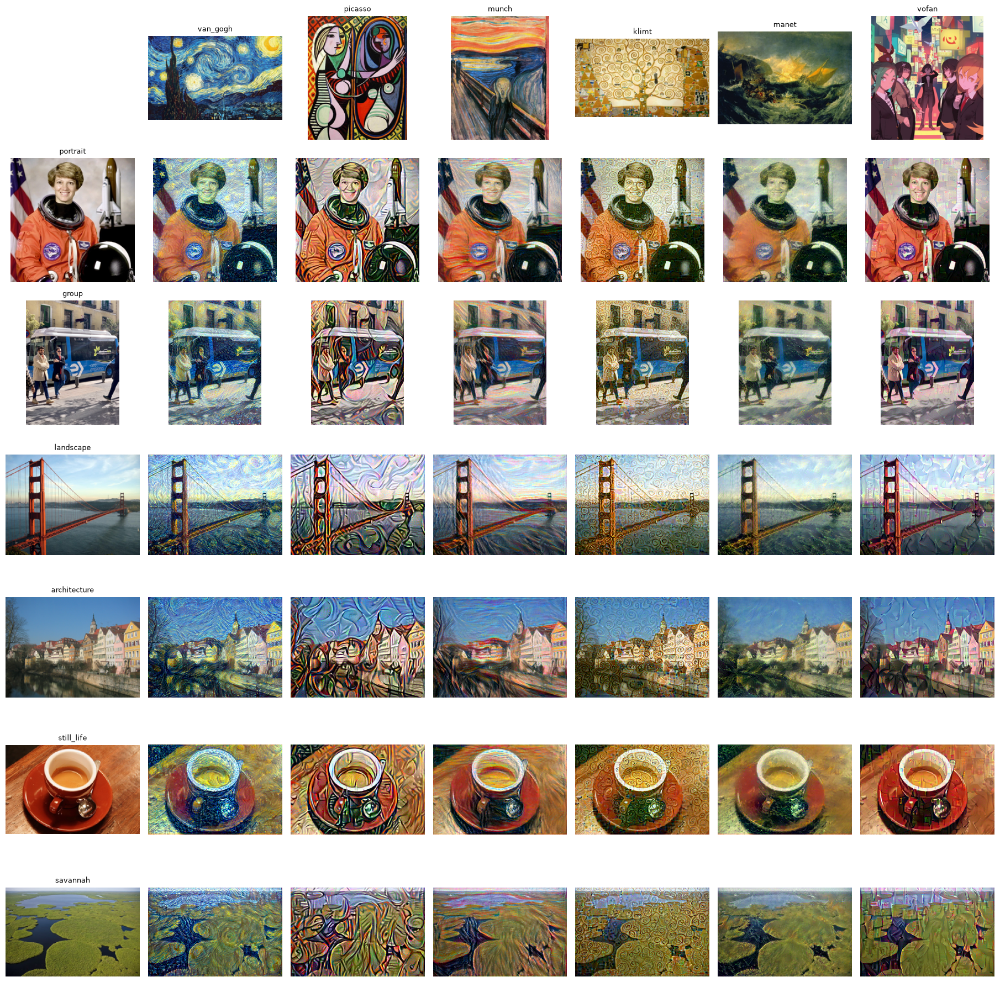

In [8]:
rows, cols = len(CONTENT), len(STYLE)
fig, axs = plt.subplots(rows + 1, cols + 1, figsize=(2.6 * (cols + 1), 2.6 * (rows + 1)))
for ax in axs.ravel():
    ax.axis("off")
for j, (sname, s) in enumerate(styles_pil.items()):
    axs[0, j + 1].imshow(load_pil(s, 200)); axs[0, j + 1].set_title(sname, fontsize=9)
for i, (cname, cpath) in enumerate(CONTENT.items()):
    axs[i + 1, 0].imshow(load_pil(cpath, 200)); axs[i + 1, 0].set_title(cname, fontsize=9)
    for j, sname in enumerate(STYLE):
        axs[i + 1, j + 1].imshow(results[(cname, sname)])
plt.tight_layout(); plt.show()

### 4.1 Training data: loss curves and summary table

Every run saved its loss values in `cache/logs/`. The plot shows how the total loss falls during the optimization. The table (also saved as `outputs/summary.csv`) lists the final loss and the time of every run.

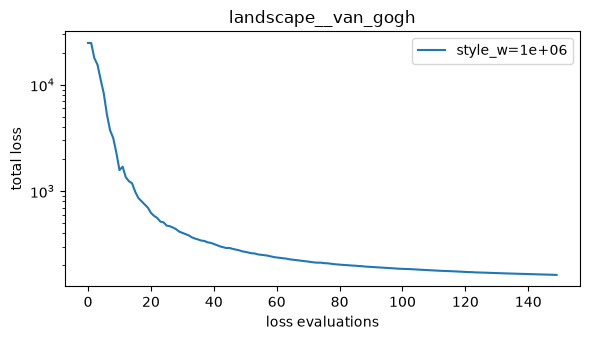

['architecture__klimt', 150, 1000000.0, '1016', '696.2', '0.0003193', 144.4]
['architecture__manet', 150, 1000000.0, '82', '52.88', '2.912e-05', 141.8]
['architecture__munch', 150, 1000000.0, '149.4', '83.98', '6.537e-05', 146.1]
['architecture__picasso', 150, 1000000.0, '965.1', '359.4', '0.0006057', 24.7]
['architecture__van_gogh', 150, 1000000.0, '143.5', '96.79', '4.674e-05', 230.5]
['architecture__vofan', 150, 1000000.0, '389.7', '140.2', '0.0002496', 156.1]
['group__klimt', 150, 1000000.0, '952.8', '684', '0.0002687', 313.9]
['group__manet', 150, 1000000.0, '139.1', '98.29', '4.082e-05', 300.7]
['group__munch', 150, 1000000.0, '181', '116.4', '6.459e-05', 303.1]
['group__picasso', 150, 1000000.0, '790', '304.2', '0.0004858', 340.9]
... 36 runs saved in outputs/summary.csv


In [9]:
import csv

def plot_losses(prefix="landscape__van_gogh"):
    files = sorted(glob.glob(f"{LOG_DIR}/{prefix}*.json"))
    plt.figure(figsize=(6, 3.5))
    for f in files:
        d = json.load(open(f))
        plt.plot([row[0] for row in d["history"]], label=f"style_w={d['params']['style_w']:.0e}")
    plt.yscale("log"); plt.xlabel("loss evaluations"); plt.ylabel("total loss"); plt.legend()
    plt.title(prefix); plt.tight_layout(); plt.show()

plot_losses("landscape__van_gogh")

rows = []
for f in sorted(glob.glob(f"{LOG_DIR}/*.json")):
    d = json.load(open(f))
    last = d["history"][-1]
    rows.append([d["name"], d["params"]["steps"], d["params"]["style_w"],
                 f"{last[0]:.4g}", f"{last[1]:.4g}", f"{last[2]:.4g}", d["seconds"]])
with open("outputs/summary.csv", "w", newline="") as fh:
    w = csv.writer(fh)
    w.writerow(["name", "steps", "style_w", "final_total", "final_content", "final_style", "seconds"])
    w.writerows(rows)
for r in rows[:10]:
    print(r)
print(f"... {len(rows)} runs saved in outputs/summary.csv")

## 5. PyTorch: control experiments

We use one photo (landscape) and one painting (Van Gogh) so the effect of each control is easy to see.

### 5.1 Content vs. style balance (a)
A small `style_w` keeps the photo almost unchanged. A large `style_w` makes the painting dominate.

All experiments are cached too. The `style_w=1e6`, `style_scale=1.0` and color runs reuse the result already computed in section 4. The color control is applied *after* the cache, so "painter's colors" and "original colors kept" cost only one computation.


[cache] landscape__van_gogh loaded from disk


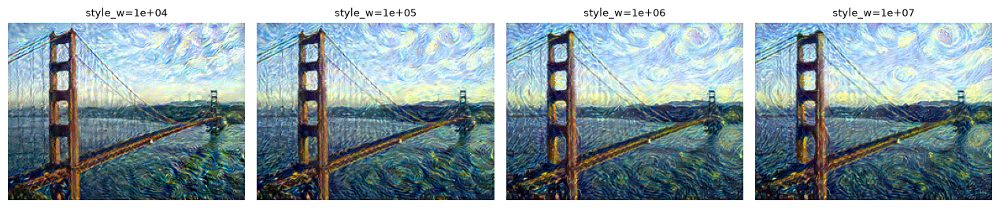

In [10]:
c = load_pil(CONTENT["landscape"], IMG_SIZE)
s = styles_pil["van_gogh"]

ws = [1e4, 1e5, 1e6, 1e7]
show_row([style_transfer(c, s, name="landscape__van_gogh", style_w=w) for w in ws], [f"style_w={w:.0e}" for w in ws])

### 5.2 Texture control (b)
First we change the **size of the painting** (`style_scale`). Then we change the **weight of each layer** (`layer_w`): shallow layers for fine texture, deep layers for coarse strokes.

[cache] landscape__van_gogh loaded from disk


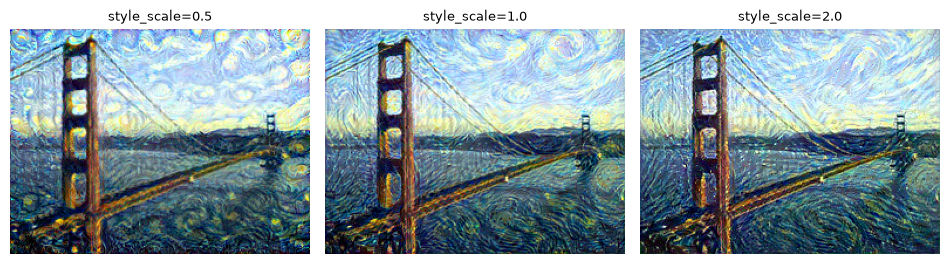

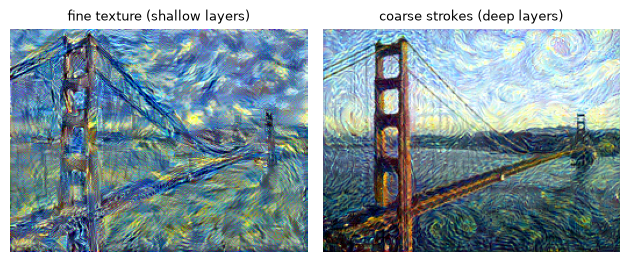

In [11]:
sc = [0.5, 1.0, 2.0]
show_row([style_transfer(c, s, name="landscape__van_gogh", style_scale=k) for k in sc], [f"style_scale={k}" for k in sc])

fine   = {"conv1_1": .4, "conv2_1": .4, "conv3_1": .2, "conv4_1": 0,  "conv5_1": 0}
coarse = {"conv1_1": 0,  "conv2_1": .1, "conv3_1": .2, "conv4_1": .4, "conv5_1": .3}
show_row([style_transfer(c, s, name="landscape__van_gogh", layer_w=fine), style_transfer(c, s, name="landscape__van_gogh", layer_w=coarse)],
         ["fine texture (shallow layers)", "coarse strokes (deep layers)"])

### 5.3 Color control (d)
Left: the original photo. Middle: the painter's colors. Right: painter's strokes but the **original colors** of the photo.

[cache] landscape__van_gogh loaded from disk
[cache] landscape__van_gogh loaded from disk


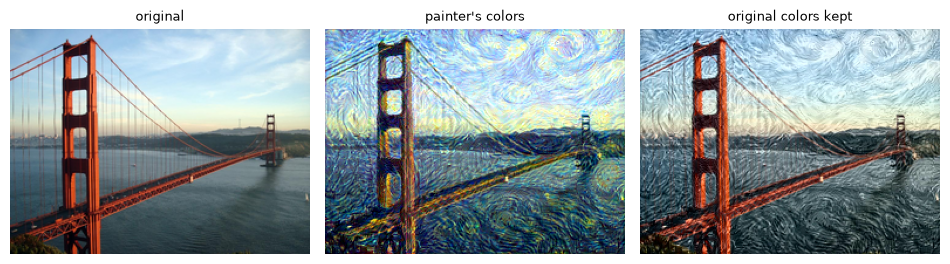

In [12]:
show_row([c, style_transfer(c, s, name="landscape__van_gogh", keep_color=False), style_transfer(c, s, name="landscape__van_gogh", keep_color=True)],
         ["original", "painter's colors", "original colors kept"])

## 6. Keras implementation

This is the same method in Keras (TensorFlow). Main differences from PyTorch:

- Keras VGG19 expects pixels in the range 0 to 255 with its own preprocessing (`preprocess_input`), so the loss weights are different (`content_w=1e4`, `style_w=1e-2`).
- We optimize with **Adam** and `tf.GradientTape`, not with L-BFGS. Adam needs more steps (300).
- We add a small **total variation** loss (`tv_w`) to remove noise.
- Layer names are `block1_conv1`, ..., `block5_conv1` (style) and `block5_conv2` (content).
- Results, checkpoints (every `K_CHUNK` steps) and loss logs are saved in the same `cache/` folders, with the prefix `keras_`. Reruns are fast and interrupted runs continue.

The Keras VGG19 weights are downloaded once and kept in `~/.keras`.

In [13]:
import tensorflow as tf
from tensorflow.keras.applications import vgg19
print("TensorFlow:", tf.__version__)
print("GPUs seen by TensorFlow:", tf.config.list_physical_devices("GPU"))

K_STEPS = 300      # Adam needs more steps than L-BFGS
K_CHUNK = 50       # checkpoint every 50 steps

K_CONTENT = "block5_conv2"
K_STYLE   = ["block1_conv1", "block2_conv1", "block3_conv1", "block4_conv1", "block5_conv1"]

base = vgg19.VGG19(include_top=False, weights="imagenet")
base.trainable = False
k_model = tf.keras.Model(base.input, [base.get_layer(n).output for n in K_STYLE + [K_CONTENT]])

def k_prep(pil):
    return tf.constant(np.array(pil, dtype=np.float32)[None] / 255.0)

def k_feats(img01):
    outs = k_model(vgg19.preprocess_input(img01 * 255.0))
    return outs[:-1], outs[-1]               # (style features, content feature)

def k_gram(f):
    g = tf.linalg.einsum("bijc,bijd->bcd", f, f)
    n = tf.cast(tf.shape(f)[1] * tf.shape(f)[2], tf.float32)
    return g / n

def k_style_transfer(content_pil, style_pil, name="run", steps=K_STEPS, content_w=1e4, style_w=1e-2,
                     tv_w=30.0, style_scale=1.0, keep_color=False, use_cache=True):
    """Keras style transfer with result cache + resumable checkpoints."""
    fname = f"keras_{name}"
    params = dict(fw="keras", size=content_pil.size, steps=steps, content_w=content_w, style_w=style_w,
                  tv_w=tv_w, style_scale=style_scale,
                  c_hash=_img_hash(content_pil), s_hash=_img_hash(style_pil))
    h = hashlib.md5(json.dumps(params, sort_keys=True, default=str).encode()).hexdigest()[:10]
    res_path = f"{RES_DIR}/{fname}_{h}.png"
    ck_path  = f"{CKPT_DIR}/{fname}_{h}.npz"
    log_path = f"{LOG_DIR}/{fname}_{h}.json"

    def finish(img):
        return keep_original_color(content_pil, img) if keep_color else img

    if use_cache and os.path.exists(res_path):
        print(f"[cache] {fname} loaded from disk")
        return finish(Image.open(res_path).convert("RGB"))

    c = k_prep(content_pil)
    s = k_prep(load_pil(style_pil, round(max(content_pil.size) * style_scale)))
    s_grams  = [k_gram(f) for f in k_feats(s)[0]]
    c_target = k_feats(c)[1]

    img = tf.Variable(c)
    done, history = 0, []
    if use_cache and os.path.exists(ck_path):
        ck = np.load(ck_path)
        img.assign(ck["x"]); done = int(ck["done"]); history = ck["history"].tolist()
        print(f"[resume] {fname} from step {done}/{steps}")

    opt = tf.keras.optimizers.Adam(learning_rate=0.02, beta_1=0.99, epsilon=1e-1)

    @tf.function
    def step():
        with tf.GradientTape() as tape:
            s_f, c_f = k_feats(img)
            s_loss = tf.add_n([tf.reduce_mean((k_gram(f) - g) ** 2)
                               for f, g in zip(s_f, s_grams)]) / len(s_grams)
            c_loss = tf.reduce_mean((c_f - c_target) ** 2)
            tv     = tf.reduce_sum(tf.image.total_variation(img))
            loss   = style_w * s_loss + content_w * c_loss + tv_w * tv
        grad = tape.gradient(loss, img)
        opt.apply_gradients([(grad, img)])
        img.assign(tf.clip_by_value(img, 0, 1))
        return loss, c_loss, s_loss

    t0 = time.time()
    while done < steps:
        n = min(K_CHUNK, steps - done)
        for _ in range(n):
            l, cl, sl = step()
            history.append([float(l), float(cl), float(sl)])          # training data
        done += n
        np.savez(ck_path, x=img.numpy(), done=done, history=np.array(history))   # checkpoint

    out = Image.fromarray((img.numpy()[0] * 255).astype(np.uint8))
    out.save(res_path)
    with open(log_path, "w") as fh:
        json.dump({"name": fname, "params": params, "seconds": round(time.time() - t0, 1),
                   "columns": ["total", "content", "style"], "history": history}, fh)
    return finish(out)

TensorFlow: 2.21.0
GPUs seen by TensorFlow: []
80134624/80134624 ━━━━━━━━━━━━━━━━━━━━ 9s 0us/step


## 7. Keras: results and controls

To save time, the Keras part runs the photos in `K_PHOTOS` with all painters (default: portrait and landscape). Add more names from `CONTENT` to the list if you want more. Everything is cached, so finished images load instantly on the next run.

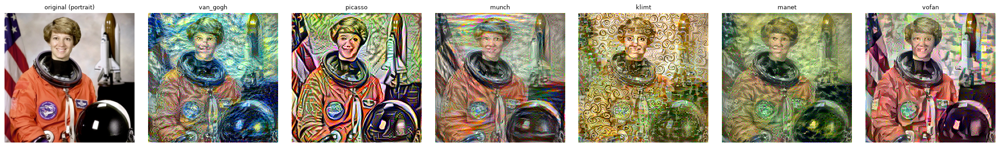

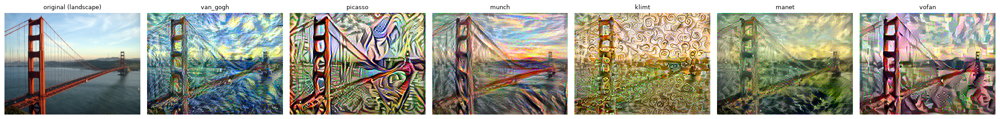

In [14]:
styles_pil = {k: Image.open(p).convert("RGB") for k, p in STYLE.items()}
K_PHOTOS = ["portrait", "landscape"]     # add more keys from CONTENT if you want

for photo in K_PHOTOS:
    kc = load_pil(CONTENT[photo], IMG_SIZE)
    k_results = {sname: k_style_transfer(kc, s, name=f"{photo}__{sname}") for sname, s in styles_pil.items()}
    show_row([kc] + list(k_results.values()), [f"original ({photo})"] + list(k_results))

[cache] keras_portrait__klimt loaded from disk


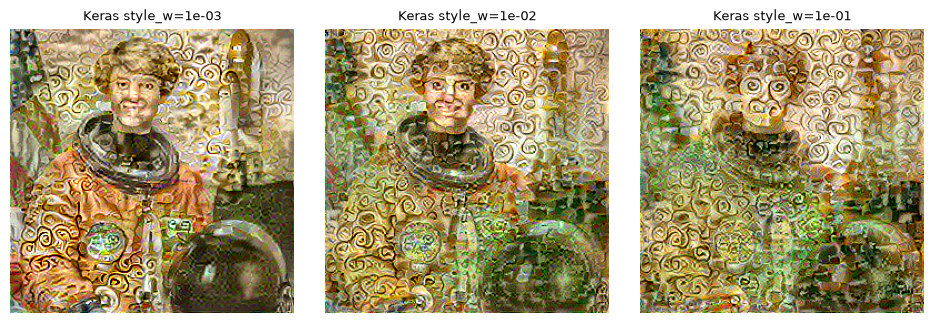

[cache] keras_portrait__klimt loaded from disk


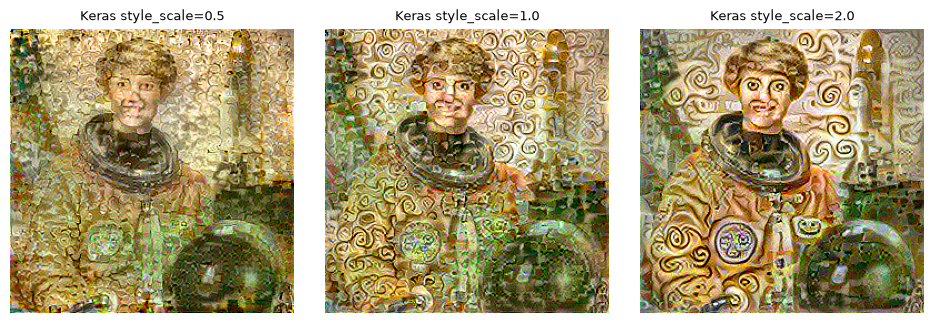

[cache] keras_portrait__klimt loaded from disk
[cache] keras_portrait__klimt loaded from disk


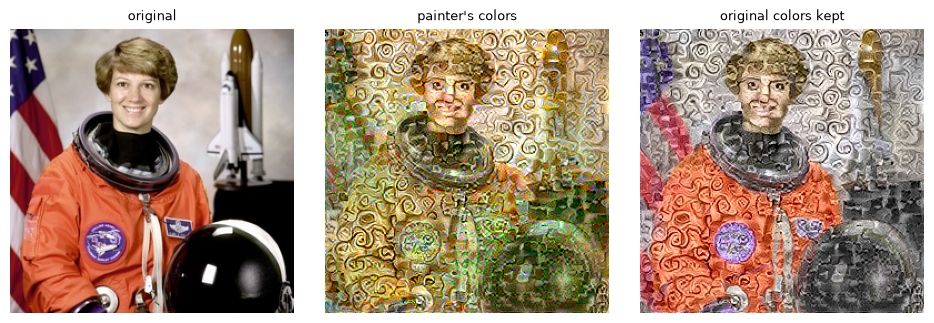

In [15]:
kc = load_pil(CONTENT["portrait"], IMG_SIZE)
s  = styles_pil["klimt"]
nm = "portrait__klimt"

# (a) Content vs. style balance
ws = [1e-3, 1e-2, 1e-1]
show_row([k_style_transfer(kc, s, name=nm, style_w=w) for w in ws], [f"Keras style_w={w:.0e}" for w in ws])

# (b) Texture: size of the painting
sc = [0.5, 1.0, 2.0]
show_row([k_style_transfer(kc, s, name=nm, style_scale=k) for k in sc], [f"Keras style_scale={k}" for k in sc])

# (d) Color (applied after the cache, so no extra computation)
show_row([kc, k_style_transfer(kc, s, name=nm), k_style_transfer(kc, s, name=nm, keep_color=True)],
         ["original", "painter's colors", "original colors kept"])

## 8. PyTorch vs. Keras comparison

We show the same pair (landscape + Munch) from both implementations. The times come from the saved logs, so they are the real optimization times of each run (not the near-zero time of loading from the cache). Note that the two use different optimizers and step counts (L-BFGS with `STEPS` vs. Adam with `K_STEPS`).

[cache] landscape__munch loaded from disk
[cache] keras_landscape__munch loaded from disk


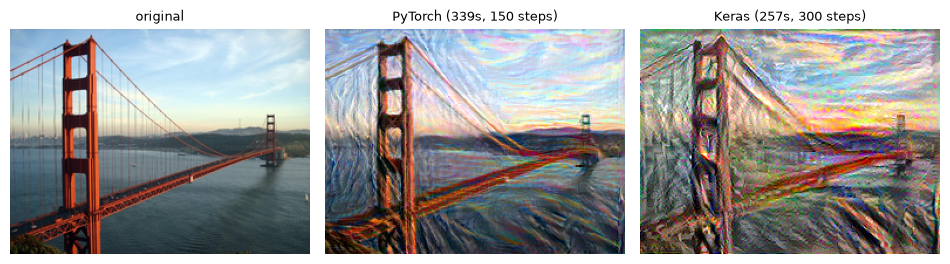

Optimization time -> PyTorch: 338.8s | Keras: 257.2s


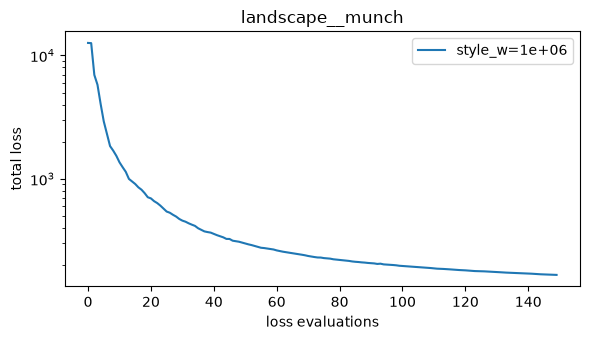

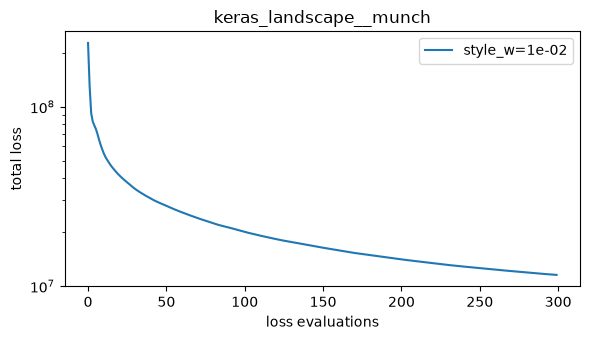

In [16]:
c = load_pil(CONTENT["landscape"], IMG_SIZE)
s = styles_pil["munch"]

out_torch = style_transfer(c, s, name="landscape__munch")
out_keras = k_style_transfer(c, s, name="landscape__munch")

def run_seconds(prefix):
    files = sorted(glob.glob(f"{LOG_DIR}/{prefix}_*.json"), key=os.path.getmtime)
    return json.load(open(files[-1]))["seconds"] if files else float("nan")

t_torch = run_seconds("landscape__munch")
t_keras = run_seconds("keras_landscape__munch")

show_row([c, out_torch, out_keras],
         ["original", f"PyTorch ({t_torch:.0f}s, {STEPS} steps)", f"Keras ({t_keras:.0f}s, {K_STEPS} steps)"])
print(f"Optimization time -> PyTorch: {t_torch:.1f}s | Keras: {t_keras:.1f}s")
plot_losses("landscape__munch")
plot_losses("keras_landscape__munch")

### Results of the comparison (landscape + Munch, same machine: Windows, Python 3.11.9, CPU only)

| | PyTorch | Keras (TensorFlow) |
|---|---|---|
| Version | 2.15.0 (CPU) | 2.21.0 (CPU) |
| Optimizer | L-BFGS | Adam (learning rate 0.02) |
| Steps | 150 | 300 |
| Optimization time | **339 s** | **257 s** |
| Loss weights | `content_w=1`, `style_w=1e6` | `content_w=1e4`, `style_w=1e-2`, `tv_w=30` |
| Input range | 0 to 1, normalized with ImageNet mean and std | 0 to 255, Keras `preprocess_input` |
| Extra smoothing | none | total variation loss |
| GPU on this PC | not used (CPU build) | not supported on native Windows (TensorFlow 2.11 and later) |
| Checkpoint format | `.pt` | `.npz` |

**Observations**
- **Speed:** Keras was faster in this test (257 s vs. 339 s), even with twice as many steps. One L-BFGS step can call the network several times, so 150 steps in PyTorch cost more than 150 forward and backward passes. Adam does exactly one pass per step. In PyTorch the time of the 36 runs changed a lot (from about 25 s to about 340 s), because L-BFGS can stop early when it decides it has converged.
- **Look of the result:** the PyTorch image looks smoother and more painterly, with brush-like strokes that follow the shapes. The Keras image has more saturated colors and more small, noisy detail. The total variation loss reduces the noise, but it does not remove it.
- **Code:** both are short. PyTorch needs a `closure` function for L-BFGS and manual normalization. Keras needs `GradientTape`, `tf.function`, and `preprocess_input`. Keras was easier for the training loop, and PyTorch was easier for debugging because the code runs line by line.
- **Loss weights are not comparable:** the numbers are different because the two networks use different input scales and different Gram normalization, so each framework needs its own `style_w`.

**Limits of this comparison:** it uses one image pair, one run per framework, and different optimizers and step counts. It is a practical test on this PC, not a strict benchmark.

## 9. Conclusions and references

**Conclusions**
- Neural style transfer works by keeping the deep features of the photo (content) and matching the Gram matrices of the painting (style). A pretrained VGG19 does the analysis, and only the pixels of the image are optimized.
- We produced **36 stylized images** (6 photos x 6 painters) in PyTorch. The same method in Keras gave similar results, so the idea does not depend on the framework.
- We implemented three controls:
  - **(a) Content vs. style balance (`style_w`):** the effect is real but mild between 1e4 and 1e7, because all of these values already give a strongly painted image. To see a bigger change, test smaller values such as 1e2 and 1e3.
  - **(b) Texture (`style_scale`, `layer_w`):** a bigger painting gives bigger swirls and a smaller one gives finer strokes. Shallow layers control fine texture and deep layers control large shapes.
  - **(d) Color:** this was the clearest control. Keeping the brightness of the stylized image and the color of the photo keeps the brush work but the scene stays natural (red bridge, blue sky).
- PyTorch with L-BFGS gave smoother, more painterly images. Keras with Adam was faster in our test (257 s vs. 339 s) but its images were more saturated and noisier.
- Saving results, checkpoints and loss logs in `cache/` made reruns almost instant (0 s per cached image) and protected long runs from interruptions. The loss logs also gave us the training data for the plots and for `summary.csv`.
- The whole project runs on a normal PC without a GPU, as the assignment asks.

**Limits and possible improvements**
- Images are small (256 px) to keep CPU time low. A GPU or a larger `IMG_SIZE` would give sharper results.
- Each image needs its own optimization (minutes on CPU). Fast feed-forward models (Johnson et al., 2016) could stylize an image in a fraction of a second after training.
- A photorealism control (option c of the assignment) could be added to avoid distortions of straight lines and faces.

**References**
- Gatys, Ecker, Bethge (2016). *Image Style Transfer Using Convolutional Neural Networks.* CVPR.
- Gatys et al. (2017). *Controlling Perceptual Factors in Neural Style Transfer.* CVPR.
- Johnson, Alahi, Fei-Fei (2016). *Perceptual Losses for Real-Time Style Transfer and Super-Resolution.* ECCV.
- PyTorch tutorial: *Neural Transfer Using PyTorch.*
- TensorFlow tutorial: *Neural style transfer.*